# 04 · RQ2 · Loops: vòng tiền đi đúng thứ tự thời gian

**RQ2.** Dòng tiền quay về điểm xuất phát qua một **vòng ACH gồm 3–6 tài khoản, đi đúng thứ tự thời gian**, có phải dấu hiệu rửa tiền không? Thứ tự thời gian có thêm thông tin so với vòng tĩnh và so với "hai đầu cùng SCC" không?

Notebook đọc đầu ra của `01_eda.ipynb` và `02_graph.ipynb`, ghi kết quả vào `reports/rq2/`. Danh sách vòng ở đây là đầu vào của RQ3 (`05_rq3_bank_view.ipynb`).

| Bước | Cách làm | Căn cứ |
|---|---|---|
| 1 | Ghép `Patterns.txt` với giao dịch; mô tả các attempt CYCLE (trần recall); chọn **δ = phân vị 95% thời lượng attempt CYCLE đóng vòng trong dev** (hiệu chỉnh trên dev) | Kumar & Calders (2018) |
| 2 | Trên R của từng đoạn: SCC, chỉ giữ SCC ≥ 2 tài khoản (mọi vòng có hướng nằm gọn trong một SCC) | Tarjan (1972) |
| 3 | Liệt kê vòng đơn tĩnh, mỗi vòng một lần, gốc tại đỉnh nhỏ nhất (như Johnson, 1975): dài 2–12 trên ACH, 2–6 trên mọi định dạng | Johnson (1975) |
| 4 | Trên T: với mỗi vòng và mọi cách xoay vòng, có tồn tại dãy giao dịch thật với thời điểm **tăng nghiêm ngặt** và thời lượng ≤ δ không. Gắn cờ mọi giao dịch nằm trên ít nhất một dãy hợp lệ | |
| 5 | Đánh giá cấp giao dịch so với chọn ngẫu nhiên, ACH-only, mẫu ACH ngẫu nhiên cùng số cảnh báo, vòng tĩnh, "hai đầu cùng SCC"; cấp attempt CYCLE | Wilson (1927) |
| 6 | Đọc kết quả: bảng độ dài vòng, **time-shuffle null**, **số ring**, typology, ba vòng minh họa | |
| 7 | Kết luận: **Đào sâu** nếu cận dưới Wilson > ACH-only và precision > vòng tĩnh và > SCC trên test, và cũng vậy trên dev, với ≥ 20 giao dịch dương; **Điều chỉnh** nếu chỉ thắng ACH-only; **Dừng** nếu không | |

Mỗi vòng phải nằm gọn trong một đoạn (dev / test / đuôi). Quy tắc chính: **ACH, dài 3–6, tăng nghiêm ngặt, ≤ δ**. Các biến thể "không giảm (≤)", "không giới hạn δ", dài 2, dài 7–12 và mọi định dạng chỉ để báo cáo độ nhạy. Chạy lại không thay đổi gì: không có tham số nào được chỉnh sau khi xem test.

## 1. Đầu vào và cấu hình

In [1]:
import json
import math
import os
import re
import time
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

GRAPH_REL = Path("data") / "processed" / "graph" / "graph_edges.parquet"


def find_project_root():
    """HI_SMALL_ROOT nếu đã đặt; nếu không, tìm thư mục chứa đầu ra của notebook 01–02."""
    if os.environ.get("HI_SMALL_ROOT"):
        return Path(os.environ["HI_SMALL_ROOT"]).expanduser()
    here = Path.cwd()
    for folder in (Path("/kaggle/working"), here, here.parent,
                   here / "IBM_HI_Small_EDA", here.parent / "IBM_HI_Small_EDA"):
        if (folder / GRAPH_REL).is_file():
            return folder
    raise FileNotFoundError(f"Không tìm thấy {GRAPH_REL}. Chạy 01_eda.ipynb và 02_graph.ipynb trước, "
                            "hoặc đặt biến môi trường HI_SMALL_ROOT.")


ROOT = find_project_root().resolve()
PATTERNS_FILE = (Path(os.environ["HI_SMALL_PATTERNS"]).expanduser() if os.environ.get("HI_SMALL_PATTERNS")
                 else next((f / "HI-Small_Patterns.txt" for f in (ROOT / "data" / "raw", ROOT, ROOT.parent)
                            if (f / "HI-Small_Patterns.txt").is_file()), ROOT / "HI-Small_Patterns.txt"))
EDGES_FILE = ROOT / GRAPH_REL
TXN_FILE = ROOT / "data" / "processed" / "hi_small_graph_transactions.parquet"
REMOVED_FILE = ROOT / "data" / "processed" / "hi_small_removed_transactions.parquet"
PERIOD_FILE = ROOT / "reports" / "tables" / "analysis_period.json"
FX_FILE = ROOT / "reports" / "tables" / "fx_rates.csv"
OUT = ROOT / "reports" / "rq2"
OUT.mkdir(parents=True, exist_ok=True)

need = {TXN_FILE: "01_eda.ipynb", REMOVED_FILE: "01_eda.ipynb", PERIOD_FILE: "01_eda.ipynb",
        FX_FILE: "01_eda.ipynb", EDGES_FILE: "02_graph.ipynb",
        PATTERNS_FILE: "đặt HI-Small_Patterns.txt vào thư mục dự án hoặc đặt HI_SMALL_PATTERNS"}
missing = [f"  - {f} → {nb}" for f, nb in need.items() if not f.is_file()]
if missing:
    raise FileNotFoundError("Thiếu đầu vào:\n" + "\n".join(missing))
print(f"Thư mục dự án: {ROOT}")
print(f"Patterns: {PATTERNS_FILE}")

CFG = {
    "main_view": "ACH",
    "views": {"ACH": {"l_max": 12, "time_limit_s": 900}, "ALL": {"l_max": 6, "time_limit_s": 300}},
    "main_lengths": [3, 6],
    "delta_quantile": 0.95,
    "max_cycles": 2_000_000,        # mỗi view và mỗi đoạn
    "per_root_cap": 2_000,          # số vòng tối đa báo cáo từ một gốc (chặn hub)
    "min_positives": 20,
    "seed": 42,
    "null_permutations": 100,
}
period = json.loads(PERIOD_FILE.read_text(encoding="utf-8"))
SEGMENTS = ["dev", "test", "tail"]
seg_bounds = np.array([int(pd.Timestamp(period[k]).timestamp()) for k in ("main_start", "dev_end", "main_end", "data_end")])
display(pd.DataFrame({"đoạn": SEGMENTS, "bắt đầu": [period["main_start"], period["dev_end"], period["main_end"]],
                      "kết thúc (không gồm)": [period["dev_end"], period["main_end"], period["data_end"]]}))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
db = duckdb.connect()
_ = db.execute("SET threads = 4")
# Giới hạn RAM của DuckDB; phần vượt mức được ghi tạm ra đĩa thay vì làm sập kernel.
DUCKDB_TMP = ROOT / "data" / "duckdb_tmp"
DUCKDB_TMP.mkdir(parents=True, exist_ok=True)
_ = db.execute(f"SET memory_limit = '{os.environ.get('HI_SMALL_DUCKDB_MEMORY', '2GB')}'")
_ = db.execute(f"SET temp_directory = '{DUCKDB_TMP.as_posix()}'")

Thư mục dự án: D:\KLTN
Patterns: D:\KLTN\HI-Small_Patterns.txt


,đoạn,bắt đầu,kết thúc (không gồm)
0,dev,2022-09-01 00:00:00,2022-09-06 13:00:00
1,test,2022-09-06 13:00:00,2022-09-11 00:00:00
2,tail,2022-09-11 00:00:00,2022-09-18 16:19:00


## 2. Trần recall từ `Patterns.txt` và chọn δ (chỉ dùng dev)

Ghép từng dòng của `HI-Small_Patterns.txt` với `transaction_id` theo 10 cột gốc (chuỗi nguyên bản). Với mỗi attempt CYCLE: độ dài (số giao dịch), có **tăng nghiêm ngặt** theo thời gian dọc vòng không (xếp theo thời gian thì nối liền thành vòng, không có hai bước cùng phút), có toàn ACH không, thời lượng (giao dịch cuối − đầu), đoạn chứa giao dịch đóng vòng.

**δ** = phân vị 95% thời lượng của các attempt CYCLE tôn trọng thời gian **đóng vòng trong dev**, làm tròn lên theo giờ. Đây là **hiệu chỉnh trên dev** (*calibration on dev*) bằng thông tin nhãn; test và đuôi không được dùng để chọn δ.

In [2]:
BEGIN = re.compile(r"^BEGIN LAUNDERING ATTEMPT - (?P<typ>[A-Z-]+)")
END = re.compile(r"^END LAUNDERING ATTEMPT")
rows, attempt, typ, seq = [], -1, None, 0
with open(PATTERNS_FILE, encoding="utf-8-sig") as fh:
    for line in fh:
        line = line.strip()
        if not line:
            continue
        m = BEGIN.match(line)
        if m:
            attempt += 1; typ = m.group("typ"); seq = 0; continue
        if END.match(line):
            typ = None; continue
        f = line.split(",")
        rows.append([attempt, typ, seq] + f[:10]); seq += 1
pat = pd.DataFrame(rows, columns=["attempt_id", "typology", "seq", "ts_raw", "from_bank", "from_acct", "to_bank",
                                  "to_acct", "amt_received_raw", "recv_ccy", "amt_paid_raw", "pay_ccy", "payment_format"])
pat["timestamp"] = pd.to_datetime(pat.ts_raw, format="%Y/%m/%d %H:%M")
db.register("pat", pat.drop(columns="ts_raw"))
pmap = db.execute("""
    SELECT p.attempt_id, p.typology, p.seq, min(t.transaction_id) AS transaction_id
    FROM pat p JOIN read_parquet(?) t
      ON t.is_laundering = 1 AND t.timestamp = p.timestamp
     AND t.from_bank = p.from_bank AND t.from_acct = p.from_acct
     AND t.to_bank = p.to_bank AND t.to_acct = p.to_acct
     AND t.amt_paid_raw = p.amt_paid_raw AND t.pay_ccy = p.pay_ccy
     AND t.amt_received_raw = p.amt_received_raw AND t.recv_ccy = p.recv_ccy
     AND t.payment_format = p.payment_format
    GROUP BY 1, 2, 3
""", [str(TXN_FILE)]).df()
print(f"Dòng pattern: {len(pat):,}; ghép được với giao dịch trong đồ thị: {len(pmap):,} "
      f"(phần còn lại là self-loop hoặc dòng trùng nằm ngoài đồ thị)")
pmap = pmap.merge(pat[["attempt_id", "seq", "timestamp", "from_bank", "from_acct", "to_bank", "to_acct", "payment_format"]],
                  on=["attempt_id", "seq"])
pmap.to_csv(OUT / "rq2_pattern_transaction_map.csv", index=False)

def seg_of(ts_seconds):
    return np.searchsorted(seg_bounds, ts_seconds, side="right") - 1

def cycle_profile(g):
    g = g.sort_values(["timestamp", "seq"])
    src = (g.from_bank.astype(int).astype(str) + "_" + g.from_acct).tolist()
    dst = (g.to_bank.astype(int).astype(str) + "_" + g.to_acct).tolist()
    t = g.timestamp.tolist()
    chained = all(dst[i] == src[i + 1] for i in range(len(g) - 1)) and dst[-1] == src[0]
    strict = chained and all(t[i] < t[i + 1] for i in range(len(g) - 1))
    secs = g.timestamp.astype("datetime64[s]").astype(np.int64).to_numpy()
    segs = seg_of(secs)
    return pd.Series({"length": len(g), "time_respecting_strict": strict,
                      "time_respecting_nonstrict": chained, "all_ach": bool((g.payment_format == "ACH").all()),
                      "duration_h": (secs.max() - secs.min()) / 3600, "segment": int(segs.max()),
                      "single_segment": bool(segs.min() == segs.max())})

_cyc_rows = pmap[pmap.typology == "CYCLE"]
if len(_cyc_rows):
    cyc_pat = _cyc_rows.groupby("attempt_id")[_cyc_rows.columns.drop("attempt_id")].apply(cycle_profile)
else:
    cyc_pat = pd.DataFrame(columns=["length", "time_respecting_strict", "time_respecting_nonstrict", "all_ach",
                                    "duration_h", "segment", "single_segment"])
    print("Cảnh báo: không ghép được attempt CYCLE nào từ Patterns.txt.")
cyc_pat["segment_name"] = cyc_pat.segment.map(dict(enumerate(SEGMENTS)))
cyc_pat["length_class"] = pd.cut(cyc_pat.length, [0, 2, 6, 99], labels=["2", "3-6", "7+"])
ceiling = cyc_pat.groupby("segment_name").agg(
    attempts=("length", "size"), len_3_6=("length", lambda s: s.between(3, 6).sum()),
    strict=("time_respecting_strict", "sum"), all_ach=("all_ach", "sum"),
    rule_ceiling=("length", lambda s: (s.between(3, 6) & cyc_pat.loc[s.index, "time_respecting_strict"]
                                        & cyc_pat.loc[s.index, "all_ach"] & cyc_pat.loc[s.index, "single_segment"]).sum()))
ceiling.to_csv(OUT / "rq2_ceiling.csv")
display(ceiling)
display(cyc_pat.groupby("length_class", observed=False).size().rename("số attempt CYCLE theo độ dài").to_frame().T)

dev_dur = cyc_pat[(cyc_pat.segment == 0) & cyc_pat.time_respecting_strict.astype(bool)].duration_h.astype(float)
if len(dev_dur) >= 5:
    DELTA_H = float(math.ceil(np.quantile(dev_dur, CFG["delta_quantile"])))
    delta_note = f"p{int(CFG['delta_quantile']*100)} của {len(dev_dur)} attempt CYCLE tôn trọng thời gian đóng vòng trong dev"
elif cyc_pat.time_respecting_strict.astype(bool).any():
    DELTA_H = float(math.ceil(cyc_pat[cyc_pat.time_respecting_strict.astype(bool)].duration_h.max()))
    delta_note = "dev có dưới 5 attempt: lấy thời lượng lớn nhất của mọi attempt tôn trọng thời gian (cần ghi chú)"
else:
    DELTA_H = 72.0
    delta_note = "không có attempt CYCLE tôn trọng thời gian: dùng 72 giờ (cần ghi chú)"
DELTA_S = int(DELTA_H * 3600)
print(f"δ = {DELTA_H:.0f} giờ ({delta_note})")

Dòng pattern: 3,209; ghép được với giao dịch trong đồ thị: 3,198 (phần còn lại là self-loop hoặc dòng trùng nằm ngoài đồ thị)


,attempts,len_3_6,strict,all_ach,rule_ceiling
segment_name,,,,,
dev,18,6,16,18,5
tail,11,2,9,11,0
test,25,12,24,25,5


length_class,2,3-6,7+
số attempt CYCLE theo độ dài,14,20,20


δ = 89 giờ (p95 của 16 attempt CYCLE tôn trọng thời gian đóng vòng trong dev)


## 3. Thuật toán: liệt kê vòng và kiểm tra thứ tự thời gian

- **Liệt kê** (trên R): mỗi vòng đơn được tìm đúng một lần, gốc tại tài khoản có chỉ số nhỏ nhất; chỉ đi qua đỉnh lớn hơn gốc, trong cùng SCC, và chỉ khi còn quay về gốc kịp trong số bước còn lại (BFS ngược từ gốc).
- **Thứ tự thời gian** (trên T): với mỗi cách xoay vòng và mỗi thời điểm bắt đầu, đi tham lam theo cạnh sớm nhất hợp lệ để ra thời điểm đóng vòng sớm nhất; nếu ≤ δ thì đi lùi từ hạn chót để lấy thời điểm muộn nhất ở mỗi bước. Mọi cạnh song song nằm giữa hai mốc đó đều thuộc một dãy hợp lệ.
- **Kiểm chứng**: cuối ô, kết quả được so với vét cạn mọi tổ hợp cạnh trên 150 đồ thị ngẫu nhiên nhỏ (có cạnh song song, giao dịch cùng phút, mọi cách xoay vòng, nhiều giá trị δ).

In [3]:
import time
from bisect import bisect_left, bisect_right

import numpy as np


def enumerate_cycles(adj_out, adj_in, comp, l_min, l_max, max_cycles, deadline, per_root_cap=10**9):
    """Simple directed cycles with l_min..l_max edges, each reported once (rooted at its smallest node).

    adj_out/adj_in: lists of sorted neighbour lists over local nodes 0..n-1.
    comp: SCC id per node; a cycle never leaves its SCC.
    per_root_cap bounds the cycles reported from one root, so a hub cannot exhaust the budget.
    Returns (cycles, roots_done, truncated_reason, roots_capped).
    """
    n = len(adj_out)
    cycles = []
    capped = 0
    for s in range(n):
        if time.monotonic() > deadline:
            return cycles, s, "time", capped
        cs = comp[s]
        # reverse BFS: distance (in edges) from y back to s, over nodes > s in the same SCC
        dist = {s: 0}
        frontier = [s]
        for d in range(1, l_max):
            nxt = []
            for x in frontier:
                for y in adj_in[x]:
                    if y > s and y not in dist and comp[y] == cs:
                        dist[y] = d
                        nxt.append(y)
            if not nxt:
                break
            frontier = nxt
        if len(dist) == 1 and s not in adj_out[s]:
            continue
        path = [s]
        onpath = {s}
        stack = [iter(adj_out[s])]
        found = 0
        while stack:
            it = stack[-1]
            k = len(path)
            moved = False
            for y in it:
                if y == s:
                    if k >= l_min:
                        cycles.append(tuple(path))
                        found += 1
                        if len(cycles) >= max_cycles:
                            return cycles, s, "max_cycles", capped
                    continue
                dy = dist.get(y)
                if dy is not None and y not in onpath and k + dy <= l_max:
                    path.append(y)
                    onpath.add(y)
                    stack.append(iter(adj_out[y]))
                    moved = True
                    break
            if not moved or found >= per_root_cap:
                if found >= per_root_cap:
                    capped += 1
                    break
                stack.pop()
                onpath.discard(path.pop())
    return cycles, n, "", capped


def temporal_check(steps, strict, delta):
    """steps: list of (times_list, ids_list) for the L pairs of a cycle in cycle order, times sorted.

    Tries every rotation and every start time. A chain is valid if times increase along the cycle
    (strictly if `strict`) and last - first <= delta.
    Returns (valid, flagged_ids:set, witness) where witness = (start_t, end_t, [ids]) of the
    earliest-closing valid chain.
    """
    L = len(steps)
    nxt = bisect_right if strict else bisect_left       # first index with time > / >= cur
    prv = bisect_left if strict else bisect_right       # count of times < / <= bound
    flagged = set()
    witness = None
    for r in range(L):
        st = steps[r:] + steps[:r]
        t0, id0 = st[0]
        last_start = None
        for a_idx, a in enumerate(t0):
            if a == last_start:
                continue
            last_start = a
            cur = a
            lo_idx = [a_idx]
            ok = True
            for i in range(1, L):
                ti = st[i][0]
                j = nxt(ti, cur)
                if j == len(ti):
                    ok = False
                    break
                cur = ti[j]
                lo_idx.append(j)
            if not ok:
                break            # later starts cannot complete either
            if cur - a > delta:
                continue
            D = a + delta
            hi_idx = [0] * L
            bound = D
            feasible = True
            for i in range(L - 1, 0, -1):
                ti = st[i][0]
                # last index with time <= bound (for the closing step) or < next step time
                if i == L - 1:
                    h = bisect_right(ti, bound) - 1
                else:
                    h = prv(ti, bound) - 1
                if h < lo_idx[i]:
                    feasible = False
                    break
                hi_idx[i] = h
                bound = ti[h]
            if not feasible:
                continue
            # step 0: every edge at the start time
            j0 = bisect_left(t0, a)
            j1 = bisect_right(t0, a)
            flagged.update(id0[j0:j1])
            for i in range(1, L):
                flagged.update(st[i][1][lo_idx[i]:hi_idx[i] + 1])
            if witness is None or cur < witness[1]:
                witness = (a, cur, [id0[a_idx]] + [st[i][1][lo_idx[i]] for i in range(1, L)])
    return witness is not None, flagged, witness


# Self-test against brute force on random small multigraphs (parallel edges, ties, all rotations).
import itertools, random
def _brute(edges, l_max, strict, delta):
    by = {}
    for u, v, t, i in edges:
        by.setdefault((u, v), []).append((t, i))
    nodes = sorted({x for e in edges for x in e[:2]})
    flagged = set()
    for L in range(2, l_max + 1):
        for perm in itertools.permutations(nodes, L):
            if perm[0] != min(perm):
                continue
            pairs = [(perm[k], perm[(k + 1) % L]) for k in range(L)]
            if not all(p in by for p in pairs):
                continue
            for r in range(L):
                pr = pairs[r:] + pairs[:r]
                for combo in itertools.product(*[by[p] for p in pr]):
                    ts_ = [x[0] for x in combo]
                    if all((ts_[k] < ts_[k + 1]) if strict else (ts_[k] <= ts_[k + 1]) for k in range(L - 1)) \
                            and ts_[-1] - ts_[0] <= delta:
                        flagged.update(x[1] for x in combo)
    return flagged
def _ours(edges, l_max, strict, delta):
    nodes = sorted({x for e in edges for x in e[:2]}); ix = {v: k for k, v in enumerate(nodes)}; n = len(nodes)
    pairs = sorted({(ix[u], ix[v]) for u, v, _, _ in edges}); a = np.array(pairs)
    _, comp = connected_components(coo_matrix((np.ones(len(a)), (a[:, 0], a[:, 1])), shape=(n, n)),
                                   directed=True, connection="strong")
    out = [[] for _ in range(n)]; inn = [[] for _ in range(n)]
    for x, y in pairs:
        if comp[x] == comp[y]:
            out[x].append(y); inn[y].append(x)
    cycles, _, _, _ = enumerate_cycles(out, inn, comp, 2, l_max, 10**9, time.monotonic() + 60)
    by = {}
    for u, v, t, i in sorted(edges, key=lambda e: (e[2], e[3])):
        by.setdefault((ix[u], ix[v]), ([], [])); by[(ix[u], ix[v])][0].append(t); by[(ix[u], ix[v])][1].append(i)
    flagged = set()
    for c in cycles:
        ok, f, _ = temporal_check([by[(c[k], c[(k + 1) % len(c)])] for k in range(len(c))], strict, delta)
        flagged |= f
    return flagged
_rng = random.Random(1)
for _ in range(150):
    n = _rng.randint(3, 6)
    E = [(_rng.randrange(n), _rng.randrange(n), _rng.randint(0, 6), k) for k in range(_rng.randint(3, 12))]
    E = [e for e in E if e[0] != e[1]]
    if E:
        for strict in (True, False):
            for delta in (2, 4, 10**9):
                assert _brute(E, 4, strict, delta) == _ours(E, 4, strict, delta), E
print("Đối chiếu với vét cạn: khớp trên 150 đồ thị nhỏ (cạnh song song, cùng phút, xoay vòng, δ).")

Đối chiếu với vét cạn: khớp trên 150 đồ thị nhỏ (cạnh song song, cùng phút, xoay vòng, δ).


## 4. Chạy trên từng view và từng đoạn

Mỗi lượt (view × đoạn) ghi: số cạnh, số cặp, số tài khoản trong SCC ≥ 2, SCC lớn nhất, số vòng tĩnh theo độ dài, có chạm giới hạn thời gian hay số vòng không. Danh sách vòng đúng thứ tự thời gian được ghi vào `rq2_loops_<view>_<đoạn>.csv`, mỗi dòng có `witness_ids` (một dãy giao dịch hợp lệ đóng vòng sớm nhất).

In [4]:
edges = db.execute("""
    SELECT transaction_id, source_id, target_id, timestamp_s, payment_format = 'ACH' AS is_ach, usd_paid
    FROM read_parquet(?) WHERE timestamp_s >= ? AND timestamp_s < ?
""", [str(EDGES_FILE), int(seg_bounds[0]), int(seg_bounds[-1])]).df()
E_src = edges.source_id.to_numpy(np.int64); E_dst = edges.target_id.to_numpy(np.int64)
E_t = edges.timestamp_s.to_numpy(np.int64); E_id = edges.transaction_id.to_numpy(np.int64)
E_ach = edges.is_ach.to_numpy(bool); E_usd = edges.usd_paid.to_numpy(float)
E_seg = seg_of(E_t)
usd_of = dict(zip(E_id.tolist(), E_usd.tolist()))
print(f"Cạnh trong kỳ chính và đuôi: {len(edges):,}")

VARIANTS = {"strict_delta": (True, DELTA_S), "nonstrict_delta": (False, DELTA_S), "strict_nodelta": (True, 10**12)}

def run_view(view, seg, l_max):
    t_start = time.monotonic()
    m = (E_seg == seg) & (E_ach if view == "ACH" else True)
    u, v, t, ids = E_src[m], E_dst[m], E_t[m], E_id[m]
    if len(u) == 0:
        return None
    nodes, inv = np.unique(np.r_[u, v], return_inverse=True)
    lu, lv = inv[:len(u)], inv[len(u):]
    n = len(nodes)
    pk = lu * n + lv
    order = np.lexsort((ids, t, pk))
    pk_s, t_s, id_s = pk[order], t[order], ids[order]
    upk, first = np.unique(pk_s, return_index=True)
    last = np.r_[first[1:], len(pk_s)]
    pu, pv = upk // n, upk % n
    _, comp = connected_components(coo_matrix((np.ones(len(pu)), (pu, pv)), shape=(n, n)), directed=True, connection="strong")
    sizes = np.bincount(comp)
    keep = (comp[pu] == comp[pv]) & (sizes[comp[pu]] >= 2)
    # SCC baseline: every edge whose two ends lie in the same non-trivial SCC
    scc_edge_ids = set()
    for a_, b_ in zip(first[keep].tolist(), last[keep].tolist()):
        scc_edge_ids.update(id_s[a_:b_].tolist())
    # Root order: accounts with fewer counterparties first, so each cycle is found from its quietest member
    # and a hub cannot use up the budget before the other accounts are visited.
    deg = np.bincount(pu[keep], minlength=n) + np.bincount(pv[keep], minlength=n)
    rank = np.empty(n, np.int64); rank[np.lexsort((np.arange(n), deg))] = np.arange(n)
    back = np.argsort(rank)                          # rank -> local node
    comp_r = comp[back]
    out = [[] for _ in range(n)]; inn = [[] for _ in range(n)]
    for x, y in zip(rank[pu[keep]].tolist(), rank[pv[keep]].tolist()):
        out[x].append(y); inn[y].append(x)
    for lst in out: lst.sort()
    for lst in inn: lst.sort()
    limit = CFG["views"][view]["time_limit_s"]
    deadline = t_start + limit                      # whole run; enumeration may use at most half of it
    cycles_r, roots_done, trunc, roots_capped = enumerate_cycles(out, inn, comp_r, 2, l_max, CFG["max_cycles"],
                                                                 t_start + limit / 2, CFG["per_root_cap"])
    cycles = [tuple(int(back[x]) for x in c) for c in cycles_r]
    pair_rng = {int(k): (int(a_), int(b_)) for k, a_, b_ in zip(upk[keep], first[keep], last[keep])}
    cache = {}
    def step(x, y):
        k = x * n + y
        if k not in cache:
            a_, b_ = pair_rng[k]
            cache[k] = (t_s[a_:b_].tolist(), id_s[a_:b_].tolist())
        return cache[k]
    recs = []
    static_loops = []                               # mọi vòng tĩnh, theo node_id toàn cục
    flagged = {name: {} for name in VARIANTS}       # variant -> length -> set(ids)
    static = {}                                     # length -> set(ids)
    n_static_by_len = {}
    checked = 0
    for c in cycles:
        if time.monotonic() > deadline:
            trunc = trunc or "time"
            break
        L = len(c)
        steps = [step(c[k], c[(k + 1) % L]) for k in range(L)]
        static.setdefault(L, set()).update(i for s_ in steps for i in s_[1])
        static_loops.append(tuple(int(nodes[x]) for x in c))
        rec = {"length": L, "accounts": " > ".join(str(int(nodes[x])) for x in c)}
        for name, (strict, delta) in VARIANTS.items():
            ok, f, w = temporal_check(steps, strict, delta)
            rec[name] = ok
            if ok:
                flagged[name].setdefault(L, set()).update(f)
                if name == "strict_delta":
                    rec.update({"start_ts": w[0], "end_ts": w[1], "witness_ids": " ".join(map(str, w[2])),
                                "witness_usd": " ".join(f"{usd_of[i]:.0f}" for i in w[2])})
        if rec["strict_delta"] or rec["nonstrict_delta"] or rec["strict_nodelta"]:
            recs.append(rec)                         # keep only time-respecting cycles on disk
        n_static_by_len[L] = n_static_by_len.get(L, 0) + 1
        checked += 1
    log = {"view": view, "segment": SEGMENTS[seg], "edges": int(m.sum()), "pairs": int(len(upk)),
           "scc_nodes": int((sizes[comp] >= 2).sum()), "largest_scc": int(sizes.max()),
           "static_cycles": len(cycles), "cycles_checked": checked, "temporal_cycles_saved": len(recs),
           "roots_done": int(roots_done), "roots_total": n, "roots_hitting_cap": int(roots_capped),
           "static_by_length": json.dumps(dict(sorted(n_static_by_len.items()))), "truncated": trunc, "seconds": round(time.monotonic() - t_start, 1)}
    return {"cycles": pd.DataFrame(recs), "flagged": flagged, "static": static, "scc": scc_edge_ids, "log": log,
            "static_loops": static_loops}

results, logs = {}, []
for view in ("ACH", "ALL"):
    for seg in range(len(SEGMENTS)):
        r = run_view(view, seg, CFG["views"][view]["l_max"])
        if r is None:
            continue
        results[(view, seg)] = r
        logs.append(r["log"])
        print(r["log"], flush=True)
        cyc = r["cycles"]
        if len(cyc):
            cyc.insert(0, "cycle_id", np.arange(len(cyc)))
            cyc.to_csv(OUT / f"rq2_loops_{view}_{SEGMENTS[seg]}.csv", index=False)
run_log = pd.DataFrame(logs)
run_log.to_csv(OUT / "rq2_run_log.csv", index=False)
display(run_log)
if run_log.truncated.astype(bool).any() or (run_log.roots_hitting_cap > 0).any():
    print("Cảnh báo: một số lượt chạm giới hạn (số chu trình, thời gian, hoặc số chu trình mỗi gốc): số chu trình và "
          "số giao dịch bị gắn cờ của các lượt đó là cận dưới. Xem cột truncated / roots_hitting_cap.")
if not (run_log.truncated.astype(bool).any() or (run_log.roots_hitting_cap > 0).any()):
    print("Không lượt nào chạm giới hạn thời gian, số vòng hay số vòng mỗi gốc: kết quả là đầy đủ.")

Cạnh trong kỳ chính và đuôi: 4,487,124
{'view': 'ACH', 'segment': 'dev', 'edges': 298120, 'pairs': 163258, 'scc_nodes': 2227, 'largest_scc': 10, 'static_cycles': 1249, 'cycles_checked': 1249, 'temporal_cycles_saved': 1206, 'roots_done': 209931, 'roots_total': 209931, 'roots_hitting_cap': 0, 'static_by_length': '{"2": 1145, "3": 89, "4": 9, "5": 1, "6": 1, "7": 1, "10": 3}', 'truncated': '', 'seconds': 2.2}
{'view': 'ACH', 'segment': 'test', 'edges': 230611, 'pairs': 115185, 'scc_nodes': 1585, 'largest_scc': 12, 'static_cycles': 884, 'cycles_checked': 884, 'temporal_cycles_saved': 849, 'roots_done': 156284, 'roots_total': 156284, 'roots_hitting_cap': 0, 'static_by_length': '{"2": 800, "3": 53, "4": 18, "5": 6, "6": 4, "7": 2, "12": 1}', 'truncated': '', 'seconds': 1.5}
{'view': 'ACH', 'segment': 'tail', 'edges': 715, 'pairs': 645, 'scc_nodes': 11, 'largest_scc': 3, 'static_cycles': 9, 'cycles_checked': 9, 'temporal_cycles_saved': 7, 'roots_done': 716, 'roots_total': 716, 'roots_hitting_

,view,segment,edges,pairs,scc_nodes,largest_scc,static_cycles,cycles_checked,temporal_cycles_saved,roots_done,roots_total,roots_hitting_cap,static_by_length,truncated,seconds
0,ACH,dev,298120,163258,2227,10,1249,1249,1206,209931,209931,0,"{""2"": 1145, ""3"": 89, ""4"": 9, ""5"": 1, ""6"": 1, ""...",,2.2
1,ACH,test,230611,115185,1585,12,884,884,849,156284,156284,0,"{""2"": 800, ""3"": 53, ""4"": 18, ""5"": 6, ""6"": 4, ""...",,1.5
2,ACH,tail,715,645,11,3,9,9,7,716,716,0,"{""2"": 7, ""3"": 2}",,0.1
3,ALL,dev,2487578,569020,7676,4578,1367,1367,1316,406927,406927,0,"{""2"": 1249, ""3"": 97, ""4"": 11, ""5"": 5, ""6"": 5}",,8.9
4,ALL,test,1998831,424106,1705,15,941,941,907,369458,369458,0,"{""2"": 859, ""3"": 53, ""4"": 18, ""5"": 6, ""6"": 5}",,5.8
5,ALL,tail,715,645,11,3,9,9,7,716,716,0,"{""2"": 7, ""3"": 2}",,0.1


Không lượt nào chạm giới hạn thời gian, số vòng hay số vòng mỗi gốc: kết quả là đầy đủ.


## 5. Đánh giá cấp giao dịch

Mẫu số = **mọi giao dịch của đoạn trong file gốc** (kể cả self-loop và dòng trùng). Một giao dịch thuộc nhiều vòng chỉ tính một lần. Nhãn chỉ được đọc từ đây trở đi.

In [5]:
labels = db.execute("""
    SELECT * FROM (
        SELECT transaction_id, CAST(epoch(timestamp) AS BIGINT) AS ts, payment_format = 'ACH' AS is_ach, is_laundering
        FROM read_parquet(?)
        UNION ALL
        SELECT transaction_id, CAST(epoch(timestamp) AS BIGINT), payment_format = 'ACH', is_laundering FROM read_parquet(?)
    ) ORDER BY transaction_id   -- thứ tự cố định để mẫu ngẫu nhiên lặp lại được
""", [str(TXN_FILE), str(REMOVED_FILE)]).df()
labels["seg"] = seg_of(labels.ts.to_numpy())
lab = pd.Series(labels.is_laundering.to_numpy(), index=labels.transaction_id.to_numpy())

def wilson(tp, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = tp / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)

def union_len(d, lo, hi):
    s = set()
    for L, ids in d.items():
        if lo <= L <= hi:
            s |= ids
    return s

rng = np.random.default_rng(CFG["seed"])
rows = []
lo_main, hi_main = CFG["main_lengths"]
for seg in range(len(SEGMENTS)):
    ls = labels[labels.seg == seg]
    n_tx, n_ill = len(ls), int(ls.is_laundering.sum())
    ach = ls[ls.is_ach]; n_ach, tp_ach = len(ach), int(ach.is_laundering.sum())
    base = {"segment": SEGMENTS[seg], "n_transactions": n_tx, "n_laundering": n_ill}
    def add(method, view, ids):
        ids = np.fromiter(ids, np.int64) if not isinstance(ids, np.ndarray) else ids
        k = len(ids); tp = int(lab.reindex(ids).fillna(0).sum()) if k else 0
        lo, hi = wilson(tp, k)
        rows.append({**base, "view": view, "method": method, "flagged": k, "tp": tp,
                     "precision": tp / k if k else np.nan, "wilson_lo": lo, "wilson_hi": hi,
                     "recall": tp / n_ill if n_ill else np.nan,
                     "lift_vs_random": (tp / k) / (n_ill / n_tx) if k and n_ill else np.nan})
        return k
    rows.append({**base, "view": "-", "method": "Random (expected)", "flagged": np.nan, "tp": np.nan,
                 "precision": n_ill / n_tx if n_tx else np.nan, "recall": np.nan, "lift_vs_random": 1.0})
    lo_, hi_ = wilson(tp_ach, n_ach)
    rows.append({**base, "view": "ACH", "method": "ACH-only", "flagged": n_ach, "tp": tp_ach,
                 "precision": tp_ach / n_ach if n_ach else np.nan, "wilson_lo": lo_, "wilson_hi": hi_,
                 "recall": tp_ach / n_ill if n_ill else np.nan,
                 "lift_vs_random": (tp_ach / n_ach) / (n_ill / n_tx) if n_ach and n_ill else np.nan})
    for view in ("ACH", "ALL"):
        r = results.get((view, seg))
        if r is None:
            continue
        k_main = add("RQ2 time-ordered loops 3-6 (strict, ≤δ) [MAIN]" if view == "ACH" else "RQ2 time-ordered loops 3-6 (strict, ≤δ)",
                     view, union_len(r["flagged"]["strict_delta"], lo_main, hi_main))
        add("time-ordered 3-6, non-decreasing (≤), ≤δ", view, union_len(r["flagged"]["nonstrict_delta"], lo_main, hi_main))
        add("time-ordered 3-6, strict, no δ", view, union_len(r["flagged"]["strict_nodelta"], lo_main, hi_main))
        add("time-ordered length 2 (strict, ≤δ)", view, union_len(r["flagged"]["strict_delta"], 2, 2))
        if CFG["views"][view]["l_max"] > 6:
            add("time-ordered length 7-12 (strict, ≤δ)", view, union_len(r["flagged"]["strict_delta"], 7, 12))
        add("B: static loops 3-6 (no time order)", view, union_len(r["static"], lo_main, hi_main))
        add("B: both ends in same SCC", view, r["scc"])
        if view == "ACH" and n_ach and k_main:
            draw = rng.choice(n_ach, min(k_main, n_ach), replace=False)
            add("B: random ACH sample (same size as MAIN)", view, ach.transaction_id.to_numpy()[draw])
tx_metrics = pd.DataFrame(rows)
tx_metrics.to_csv(OUT / "rq2_transaction_metrics.csv", index=False)
pd.set_option("display.max_colwidth", 60)
display(tx_metrics[tx_metrics.segment == "test"].drop(columns=["segment", "n_transactions", "n_laundering"]).round(5))

,view,method,flagged,tp,precision,recall,lift_vs_random,wilson_lo,wilson_hi
16,-,Random (expected),NaN,NaN,0.00110,NaN,1.00000,NaN,NaN
17,ACH,ACH-only,262486.0,1946.0,0.00741,0.86489,6.72850,0.00709,0.00775
18,ACH,"RQ2 time-ordered loops 3-6 (strict, ≤δ) [MAIN]",122.0,67.0,0.54918,0.02978,498.42093,0.46073,0.63463
19,ACH,"time-ordered 3-6, non-decreasing (≤), ≤δ",122.0,67.0,0.54918,0.02978,498.42093,0.46073,0.63463
20,ACH,"time-ordered 3-6, strict, no δ",143.0,79.0,0.55245,0.03511,501.38618,0.47064,0.63151
21,ACH,"time-ordered length 2 (strict, ≤δ)",1694.0,123.0,0.07261,0.05467,65.89812,0.06120,0.08596
22,ACH,"time-ordered length 7-12 (strict, ≤δ)",7.0,7.0,1.00000,0.00311,907.57244,0.64566,1.00000
23,ACH,B: static loops 3-6 (no time order),210.0,92.0,0.43810,0.04089,397.60317,0.37270,0.50572
24,ACH,B: both ends in same SCC,1826.0,189.0,0.10350,0.08400,93.93822,0.09036,0.11832
25,ACH,B: random ACH sample (same size as MAIN),122.0,4.0,0.03279,0.00178,29.75647,0.01282,0.08128


## 6. Đọc kết quả RQ2

### 6.1 Bảng độ dài vòng (test, ACH, đúng thứ tự, ≤ δ)

Mỗi vòng được chấm theo **dãy giao dịch chứng minh** (`witness_ids`) của nó: *toàn rửa tiền* nếu mọi giao dịch trong dãy có nhãn 1, *không rửa tiền* nếu không giao dịch nào có nhãn 1. Cột cấp giao dịch dùng toàn bộ giao dịch bị gắn cờ của độ dài đó.

In [6]:
def loops_of(view, seg, variant="strict_delta"):
    r = results.get((view, seg))
    if r is None or not len(r["cycles"]):
        return pd.DataFrame(columns=["cycle_id", "length", "accounts", "witness_ids"])
    c = r["cycles"]
    c = c[c[variant].astype(bool)].copy()
    c["ids"] = c.witness_ids.str.split().apply(lambda x: [int(i) for i in x])
    c["n_laundering"] = c.ids.apply(lambda x: int(lab.reindex(x).fillna(0).sum()))
    c["fully_laundering"] = c.n_laundering == c.length
    c["no_laundering"] = c.n_laundering == 0
    return c


length_rows = []
for seg in (0, 1):
    L = loops_of("ACH", seg)
    fl = results[("ACH", seg)]["flagged"]["strict_delta"]
    for length in range(2, CFG["views"]["ACH"]["l_max"] + 1):
        part = L[L.length == length]
        ids = np.fromiter(fl.get(length, set()), np.int64)
        tp = int(lab.reindex(ids).fillna(0).sum()) if len(ids) else 0
        if len(part) or len(ids):
            length_rows.append({"segment": SEGMENTS[seg], "length": length, "loops": len(part),
                                "fully_laundering": int(part.fully_laundering.sum()),
                                "no_laundering": int(part.no_laundering.sum()),
                                "flagged_tx": len(ids), "laundering_tx": tp,
                                "precision_tx": tp / len(ids) if len(ids) else np.nan})
loop_lengths = pd.DataFrame(length_rows)
loop_lengths.to_csv(OUT / "rq2_loop_lengths.csv", index=False)
display(loop_lengths[loop_lengths.segment == "test"].round(3))
t36 = loop_lengths[(loop_lengths.segment == "test") & loop_lengths.length.between(3, 6)]
print(f"Ý nghĩa: trên test có {t36.loops.sum()} vòng dài 3–6, trong đó {t36.fully_laundering.sum()} vòng toàn rửa tiền và "
      f"{t36.no_laundering.sum()} vòng không có giao dịch rửa tiền nào. Vòng 2 bước (A ⇄ B) rất phổ biến và phần lớn "
      "là giao dịch thường; vòng càng dài càng hiếm và càng sạch tín hiệu.")

,segment,length,loops,fully_laundering,no_laundering,flagged_tx,laundering_tx,precision_tx
6,test,2,776,14,737,1694,123,0.073
7,test,3,27,9,16,97,47,0.485
8,test,4,7,6,1,33,29,0.879
9,test,5,4,2,0,22,17,0.773
10,test,6,2,2,0,8,8,1.000
11,test,7,1,1,0,7,7,1.000


Ý nghĩa: trên test có 40 vòng dài 3–6, trong đó 19 vòng toàn rửa tiền và 17 vòng không có giao dịch rửa tiền nào. Vòng 2 bước (A ⇄ B) rất phổ biến và phần lớn là giao dịch thường; vòng càng dài càng hiếm và càng sạch tín hiệu.


### 6.2 Time-shuffle null: thứ tự thời gian có xuất hiện do tình cờ không?

Giữ nguyên mọi cạnh của đồ thị ACH trong test, chỉ **xáo trộn thời điểm** giữa các giao dịch (cùng tập thời điểm, thứ tự ngẫu nhiên), rồi kiểm tra lại thứ tự thời gian (tăng nghiêm ngặt, ≤ δ) trên **đúng danh sách vòng tĩnh 3–6** đã liệt kê. Danh sách vòng tĩnh không đổi, nhãn không được dùng. Lặp 100 lần với seed 42.

Nếu số vòng đúng thứ tự quan sát được cao hơn hẳn phân phối xáo trộn thì các vòng tuân thủ thứ tự thời gian nhiều hơn mức ngẫu nhiên. Nếu không, bản thân vòng khép kín mới là tín hiệu, không phải thứ tự của nó. Cả hai đều là kết quả báo cáo được. Với một giao dịch trên mỗi cạnh và thời điểm ngẫu nhiên, xác suất một vòng dài k đúng thứ tự là 1/(k−1)!: 50% với k = 3, 17% với k = 4, 4% với k = 5, 0,8% với k = 6.

,segment,static_loops_3_6,observed_time_ordered,null_mean,null_p95,null_max,p_value
0,dev,100,48,40.72,48.05,56,0.079
1,test,81,40,35.54,45.00,49,0.188


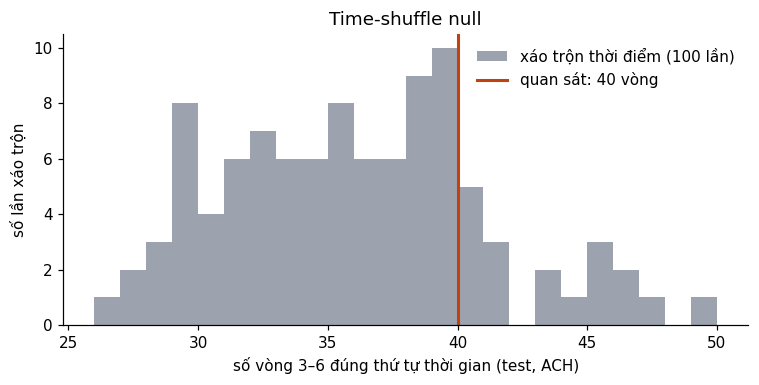

Ý nghĩa: trên test, 40/81 vòng tĩnh 3–6 đi đúng thứ tự thời gian; khi xáo trộn thời điểm, trung bình 35.5 vòng (p95 = 45, p = 0.188), nên số vòng đúng thứ tự không cao hơn mức ngẫu nhiên một cách có ý nghĩa: bản thân vòng khép kín là tín hiệu chính, còn điều kiện thời gian chủ yếu lọc bớt vòng thường (precision 43.8% của vòng tĩnh → 54.9% của vòng đúng thứ tự, mục 5).


In [7]:
def count_time_ordered(view, seg, times, lengths=(3, 6)):
    """Số vòng tĩnh dài lengths đúng thứ tự (strict, ≤ δ) khi thời điểm các cạnh của đoạn là `times`."""
    m = (E_seg == seg) & (E_ach if view == "ACH" else True)
    u, v = E_src[m], E_dst[m]
    loops = [c for c in results[(view, seg)]["static_loops"] if lengths[0] <= len(c) <= lengths[1]]
    if not hasattr(count_time_ordered, "cache") or count_time_ordered.cache[0] != (view, seg):
        need_pairs = {(c[k], c[(k + 1) % len(c)]) for c in loops for k in range(len(c))}
        key = u.astype(np.int64) * 10_000_000 + v
        need_keys = np.array(sorted(a * 10_000_000 + b for a, b in need_pairs), dtype=np.int64)
        pos = {}
        for i in np.flatnonzero(np.isin(key, need_keys)).tolist():
            pos.setdefault((int(u[i]), int(v[i])), []).append(i)
        count_time_ordered.cache = ((view, seg), {p_: np.array(ix) for p_, ix in pos.items()})
    pos = count_time_ordered.cache[1]
    by_len = {}
    for c in loops:
        steps = []
        for k in range(len(c)):
            idx = pos[(c[k], c[(k + 1) % len(c)])]
            o = np.argsort(times[idx], kind="stable")
            steps.append((times[idx][o].tolist(), idx[o].tolist()))
        ok, _, _ = temporal_check(steps, True, DELTA_S)
        by_len[len(c)] = by_len.get(len(c), 0) + int(ok)
    return by_len


null_rows = []
for seg in (0, 1):
    m = (E_seg == seg) & E_ach
    t_obs = E_t[m]
    obs = count_time_ordered("ACH", seg, t_obs)
    rng_null = np.random.default_rng(CFG["seed"])
    for r in range(CFG["null_permutations"]):
        sim = count_time_ordered("ACH", seg, rng_null.permutation(t_obs))
        null_rows += [{"segment": SEGMENTS[seg], "perm": r, "length": L, "time_ordered": n} for L, n in sim.items()]
    null_rows += [{"segment": SEGMENTS[seg], "perm": -1, "length": L, "time_ordered": n} for L, n in obs.items()]
null_df = pd.DataFrame(null_rows)
null_df.to_csv(OUT / "rq2_time_shuffle_null.csv", index=False)

summ = []
for seg_name, g in null_df.groupby("segment", sort=False):
    tot = g.groupby("perm").time_ordered.sum()
    o, sims = tot.loc[-1], tot.drop(-1)
    n_static = sum(1 for c in results[("ACH", SEGMENTS.index(seg_name))]["static_loops"] if 3 <= len(c) <= 6)
    summ.append({"segment": seg_name, "static_loops_3_6": n_static, "observed_time_ordered": int(o),
                 "null_mean": sims.mean(), "null_p95": sims.quantile(0.95), "null_max": sims.max(),
                 "p_value": ((sims >= o).sum() + 1) / (len(sims) + 1)})
null_summary = pd.DataFrame(summ)
null_summary.to_csv(OUT / "rq2_time_shuffle_null_summary.csv", index=False)
display(null_summary.round(3))

g = null_df[null_df.segment == "test"].groupby("perm").time_ordered.sum()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(g.drop(-1), bins=range(int(g.min()), int(g.max()) + 2), color="#9CA3AF", label="xáo trộn thời điểm (100 lần)")
ax.axvline(g.loc[-1], color="#C2410C", lw=2, label=f"quan sát: {int(g.loc[-1])} vòng")
ax.set_xlabel("số vòng 3–6 đúng thứ tự thời gian (test, ACH)")
ax.set_ylabel("số lần xáo trộn")
ax.set_title("Time-shuffle null")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "rq2_time_shuffle_null.png", bbox_inches="tight")
plt.show()
r_ = null_summary[null_summary.segment == "test"].iloc[0]
verdict_null = ("các vòng tuân thủ thứ tự thời gian nhiều hơn mức ngẫu nhiên" if r_.p_value < 0.05 else
                "số vòng đúng thứ tự không cao hơn mức ngẫu nhiên một cách có ý nghĩa: bản thân vòng khép kín là tín hiệu chính, "
                "còn điều kiện thời gian chủ yếu lọc bớt vòng thường (precision "
                f"{tx_metrics[(tx_metrics.segment == 'test') & (tx_metrics.view == 'ACH') & tx_metrics.method.str.startswith('B: static')].precision.iloc[0]:.1%}"
                " của vòng tĩnh → "
                f"{tx_metrics[(tx_metrics.segment == 'test') & (tx_metrics.view == 'ACH') & tx_metrics.method.str.endswith('[MAIN]')].precision.iloc[0]:.1%}"
                " của vòng đúng thứ tự, mục 5)")
print(f"Ý nghĩa: trên test, {int(r_.observed_time_ordered)}/{int(r_.static_loops_3_6)} vòng tĩnh 3–6 đi đúng thứ tự thời gian; "
      f"khi xáo trộn thời điểm, trung bình {r_.null_mean:.1f} vòng (p95 = {r_.null_p95:.0f}, p = {r_.p_value:.3f}), "
      f"nên {verdict_null}.")

### 6.3 Ring: đơn vị độc lập

Nhiều vòng có thể dùng chung tài khoản (một nhóm rửa tiền tạo ra nhiều vòng chồng lấn). Vì vậy các giao dịch đúng **không độc lập**, và khoảng Wilson (giả định độc lập) có thể hẹp hơn thực tế. Ring = nhóm tài khoản nối với nhau qua các vòng bị gắn cờ, tìm bằng union-find trên tài khoản của các vòng 3–6 (đúng thứ tự, ≤ δ).

In [8]:
def rings_of(loops):
    parent = {}

    def find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    for acc in loops.accounts:
        a = acc.split(" > ")
        for x in a[1:]:
            ra, rb = find(a[0]), find(x)
            if ra != rb:
                parent[rb] = ra
    return loops.accounts.apply(lambda s: find(s.split(" > ")[0]))


ring_rows, ring_tables = [], {}
for seg in (0, 1):
    L = loops_of("ACH", seg)
    L = L[L.length.between(*CFG["main_lengths"])].copy()
    L["ring"] = rings_of(L) if len(L) else []
    rt = L.groupby("ring").agg(loops=("cycle_id", "size"), fully_laundering=("fully_laundering", "sum"),
                               no_laundering=("no_laundering", "sum"),
                               accounts=("accounts", lambda s: len({a for x in s for a in x.split(" > ")})))
    rt = rt.sort_values(["fully_laundering", "loops"], ascending=False)
    rt.insert(0, "segment", SEGMENTS[seg])
    ring_tables[seg] = (L, rt)
    fl = rt.fully_laundering
    ring_rows.append({"segment": SEGMENTS[seg], "loops": len(L), "rings": len(rt),
                      "fully_laundering_loops": int(fl.sum()), "rings_with_fully_laundering": int((fl > 0).sum()),
                      "top2_rings_share_of_fully_laundering": fl.nlargest(2).sum() / max(fl.sum(), 1),
                      "rings_only_no_laundering": int((rt.no_laundering == rt.loops).sum())})
pd.concat([ring_tables[s][1] for s in (0, 1)]).to_csv(OUT / "rq2_rings.csv")
ring_summary = pd.DataFrame(ring_rows)
ring_summary.to_csv(OUT / "rq2_ring_summary.csv", index=False)
display(ring_summary.round(3))
display(ring_tables[1][1].head(10))
r_ = ring_summary[ring_summary.segment == "test"].iloc[0]
print(f"Ý nghĩa: {r_.loops} vòng trên test thuộc {r_.rings} ring; {r_.fully_laundering_loops} vòng toàn rửa tiền đến từ "
      f"{r_.rings_with_fully_laundering} ring, hai ring lớn nhất chiếm {r_.top2_rings_share_of_fully_laundering:.0%}. "
      "Bằng chứng độc lập là số ring, không phải số vòng hay số giao dịch: cần báo cáo số ring cạnh precision.")

,segment,loops,rings,fully_laundering_loops,rings_with_fully_laundering,top2_rings_share_of_fully_laundering,rings_only_no_laundering
0,dev,48,33,18,5,0.833,27
1,test,40,20,19,4,0.895,13


,segment,loops,fully_laundering,no_laundering,accounts
ring,,,,,
211692,test,9,9,0,8
200574,test,8,8,0,4
105153,test,2,1,0,3
12008,test,1,1,0,3
16632,test,5,0,5,4
10972,test,1,0,0,5
119370,test,1,0,0,3
132001,test,1,0,1,3
136322,test,1,0,1,3


Ý nghĩa: 40 vòng trên test thuộc 20 ring; 19 vòng toàn rửa tiền đến từ 4 ring, hai ring lớn nhất chiếm 89%. Bằng chứng độc lập là số ring, không phải số vòng hay số giao dịch: cần báo cáo số ring cạnh precision.


### 6.4 Typology và attempt CYCLE

Một attempt CYCLE được **tìm lại trọn** nếu mọi giao dịch của nó (trong đồ thị) đều bị quy tắc chính gắn cờ. Bảng thứ hai cho biết các giao dịch rửa tiền bị gắn cờ thuộc typology nào: quy tắc có chỉ bắt CYCLE không, hay bắt cả các kịch bản khác có tạo vòng.

In [9]:
prow = []
for seg in range(len(SEGMENTS)):
    r = results.get(("ACH", seg))
    flagged_main = union_len(r["flagged"]["strict_delta"], lo_main, hi_main) if r else set()
    flagged_any = union_len(r["flagged"]["strict_delta"], 2, 12) if r else set()
    for aid, g in pmap[pmap.typology == "CYCLE"].groupby("attempt_id"):
        if cyc_pat.loc[aid, "segment"] != seg:
            continue
        ids = set(g.transaction_id.tolist())
        prow.append({"segment": SEGMENTS[seg], "attempt_id": aid, "length": int(cyc_pat.loc[aid, "length"]),
                     "all_ach": cyc_pat.loc[aid, "all_ach"], "strict_in_patterns": cyc_pat.loc[aid, "time_respecting_strict"],
                     "recovered_main_3_6": ids <= flagged_main, "recovered_any_length": ids <= flagged_any,
                     "share_flagged_main": len(ids & flagged_main) / len(ids)})
pattern_rec = pd.DataFrame(prow)
pattern_rec.to_csv(OUT / "rq2_pattern_recovery.csv", index=False)
if len(pattern_rec):
    summary = pattern_rec.groupby("segment").agg(
        cycle_attempts=("attempt_id", "size"),
        recovered_main=("recovered_main_3_6", "sum"),
        recovered_any_length=("recovered_any_length", "sum"),
        partially=("share_flagged_main", lambda s: int(((s > 0) & (s < 1)).sum())))
    display(summary)

typ_rows = []
for seg in range(len(SEGMENTS)):
    r = results.get(("ACH", seg))
    if not r:
        continue
    ids = np.fromiter(union_len(r["flagged"]["strict_delta"], lo_main, hi_main), np.int64)
    pos = ids[lab.reindex(ids).fillna(0).to_numpy() == 1]
    t = pmap[pmap.transaction_id.isin(pos)].typology.value_counts()
    typ_rows.append({"segment": SEGMENTS[seg], "flagged_laundering": len(pos),
                     "not_in_any_listed_attempt": int(len(pos) - pmap.transaction_id.isin(pos).sum()), **t.to_dict()})
typology_table = pd.DataFrame(typ_rows).fillna(0)
typology_table.to_csv(OUT / "rq2_typology.csv", index=False)
display(typology_table)
tt = typology_table[typology_table.segment == "test"].iloc[0]
others = {k: int(v) for k, v in tt.items() if k not in ("segment", "flagged_laundering", "not_in_any_listed_attempt", "CYCLE") and v}
print(f"Ý nghĩa: trong {int(tt.flagged_laundering)} giao dịch rửa tiền bị gắn cờ trên test, chỉ {int(tt.get('CYCLE', 0))} "
      f"thuộc attempt CYCLE; phần còn lại thuộc {others} và {int(tt.not_in_any_listed_attempt)} không thuộc attempt nào. "
      "Các nhóm rửa tiền tạo vòng trong nhiều kịch bản, không chỉ kịch bản CYCLE.")

,cycle_attempts,recovered_main,recovered_any_length,partially
segment,,,,
dev,18,6,15,0
tail,11,0,0,0
test,25,3,7,2


,segment,flagged_laundering,not_in_any_listed_attempt,CYCLE,GATHER-SCATTER,RANDOM,FAN-IN,FAN-OUT,STACK,SCATTER-GATHER,BIPARTITE
0,dev,68,0,25.0,12.0,9.0,7.0,6.0,5.0,4.0,0.0
1,test,67,2,18.0,17.0,6.0,5.0,6.0,5.0,5.0,3.0
2,tail,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Ý nghĩa: trong 67 giao dịch rửa tiền bị gắn cờ trên test, chỉ 18 thuộc attempt CYCLE; phần còn lại thuộc {'GATHER-SCATTER': 17, 'RANDOM': 6, 'FAN-IN': 5, 'FAN-OUT': 6, 'STACK': 5, 'SCATTER-GATHER': 5, 'BIPARTITE': 3} và 2 không thuộc attempt nào. Các nhóm rửa tiền tạo vòng trong nhiều kịch bản, không chỉ kịch bản CYCLE.


### 6.5 Ba vòng minh họa

Chọn theo quy tắc cố định trên test, ACH, dài 3–6, đúng thứ tự, ≤ δ (dùng nhãn **chỉ để minh họa**, không để chọn tham số):
- vòng **toàn rửa tiền** có mọi giao dịch thuộc attempt CYCLE trong `Patterns.txt`, `cycle_id` nhỏ nhất: một vòng tiền đúng nghĩa;
- vòng **toàn rửa tiền** có `cycle_id` nhỏ nhất trong **ring lớn nhất** (mục 6.3): cho thấy một nhóm tài khoản tạo nhiều vòng chồng lấn;
- vòng **không có giao dịch rửa tiền** dài 3 có `cycle_id` nhỏ nhất: một vòng thương mại tình cờ.

Mỗi cạnh ghi thời điểm, số tiền theo tiền tệ gốc và quy USD. *Giá trị giữ lại* = số tiền USD nhỏ nhất ÷ lớn nhất dọc vòng.

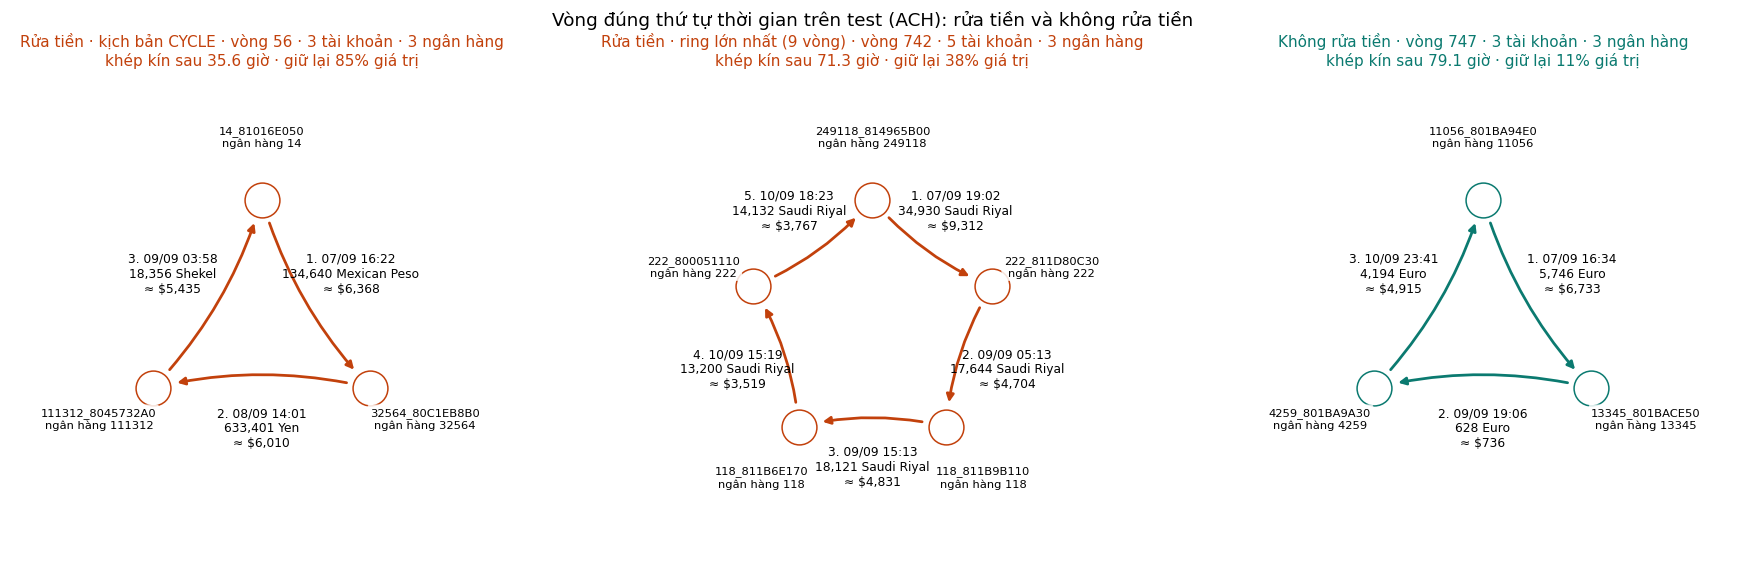

,kind,cycle_id,length,banks,currencies,hours,value_kept,ids
0,Rửa tiền · kịch bản CYCLE,56,3,3,3,35.60,0.85,3586640 3586642 3586644
1,Rửa tiền · ring lớn nhất (9 vòng),742,5,3,1,71.35,0.38,2132658 4376201 4376202 4929656 4929657
2,Không rửa tiền,747,3,3,1,79.12,0.11,3591077 4742854 5075989


In [10]:
L_test, _ = ring_tables[1]
tx_detail_cols = "transaction_id, timestamp, src, dst, from_bank_id, to_bank_id, amt_paid, pay_ccy, usd_paid"


def loop_details(ids):
    d = db.execute(f"SELECT {tx_detail_cols} FROM read_parquet(?) WHERE list_contains(?::BIGINT[], transaction_id)",
                   [str(EDGES_FILE), [int(i) for i in ids]]).df().set_index("transaction_id").loc[ids].reset_index()
    return d


def n_banks(ids):
    d = loop_details(ids)
    return len(set(d.from_bank_id) | set(d.to_bank_id))


cycle_tx = set(pmap[pmap.typology == "CYCLE"].transaction_id.astype(int))
picks = []
if len(L_test):
    fl = L_test[L_test.fully_laundering]
    pure = fl[fl.ids.apply(lambda x: all(i in cycle_tx for i in x))].sort_values("cycle_id")
    if len(pure):
        picks.append(("Rửa tiền · kịch bản CYCLE", pure.iloc[0]))
    ring_size = L_test.ring.value_counts()
    big = fl[fl.ring == ring_size.index[0]].sort_values("cycle_id")
    big = big[~big.cycle_id.isin([r.cycle_id for _, r in picks])]
    if len(big):
        picks.append((f"Rửa tiền · ring lớn nhất ({ring_size.iloc[0]} vòng)", big.iloc[0]))
    clean = L_test[L_test.no_laundering & (L_test.length == 3)].sort_values("cycle_id")
    if len(clean):
        picks.append(("Không rửa tiền", clean.iloc[0]))

fig, axes = plt.subplots(1, len(picks), figsize=(5.6 * len(picks), 5.4))
axes = np.atleast_1d(axes)
example_rows = []
for ax, (kind, row) in zip(axes, picks):
    d = loop_details(row.ids)
    n = len(d)
    ang = np.pi / 2 - 2 * np.pi * np.arange(n) / n
    pos = np.c_[np.cos(ang), np.sin(ang)]
    color = "#C2410C" if kind.startswith("Rửa tiền") else "#0B7A70"
    for i, r in d.iterrows():
        p, q = pos[i], pos[(i + 1) % n]
        ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color=color, lw=1.8,
                                                         shrinkA=16, shrinkB=16, connectionstyle="arc3,rad=0.12"))
        mid = (p + q) / 2
        out = mid / (np.linalg.norm(mid) or 1)
        ax.text(*(mid + out * 0.32), f"{i + 1}. {r.timestamp:%d/%m %H:%M}\n{r.amt_paid:,.0f} {r.pay_ccy}\n≈ ${r.usd_paid:,.0f}",
                ha="center", va="center", fontsize=8)
        ax.scatter(*p, s=520, color="white", edgecolor=color, zorder=3)
        ax.text(*(p * 1.5), f"{r.src}\nngân hàng {r.from_bank_id}", ha="center", va="center", fontsize=7.5,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
    hours = (d.timestamp.iloc[-1] - d.timestamp.iloc[0]).total_seconds() / 3600
    kept = d.usd_paid.min() / d.usd_paid.max()
    banks = len(set(d.from_bank_id) | set(d.to_bank_id))
    ax.set_title(f"{kind} · vòng {int(row.cycle_id)} · {n} tài khoản · {banks} ngân hàng\n"
                 f"khép kín sau {hours:.1f} giờ · giữ lại {kept:.0%} giá trị", fontsize=10, color=color)
    ax.set_xlim(-2.0, 2.0); ax.set_ylim(-2.0, 2.0); ax.set_aspect("equal"); ax.axis("off")
    example_rows.append({"kind": kind, "cycle_id": int(row.cycle_id), "length": n, "banks": banks,
                         "currencies": d.pay_ccy.nunique(), "hours": hours, "value_kept": kept,
                         "ids": " ".join(map(str, row.ids))})
fig.suptitle("Vòng đúng thứ tự thời gian trên test (ACH): rửa tiền và không rửa tiền", fontsize=12)
fig.tight_layout()
fig.savefig(OUT / "rq2_loop_examples.png", bbox_inches="tight")
plt.show()
examples = pd.DataFrame(example_rows)
examples.to_csv(OUT / "rq2_loop_examples.csv", index=False)
display(examples.round(2))

### 6.6 Giá trị giữ lại dọc vòng (tùy chọn, chỉ trên dev)

*Giá trị giữ lại* = số tiền USD nhỏ nhất ÷ lớn nhất trên dãy giao dịch của vòng. Ý tưởng: vòng rửa tiền chuyển gần như nguyên số tiền qua từng chặng (trừ phí), còn vòng thương mại tình cờ có số tiền không khớp nhau. Bảng **chỉ dùng dev** để mô tả; không có ngưỡng nào được chọn hay áp lên test.

In [11]:
L_dev = loops_of("ACH", 0)
L_dev = L_dev[L_dev.length.between(*CFG["main_lengths"])].copy()
usd_by_id = dict(zip(E_id.tolist(), E_usd.tolist()))
L_dev["value_kept"] = L_dev.ids.apply(lambda x: min(usd_by_id[i] for i in x) / max(usd_by_id[i] for i in x))
L_dev["group"] = np.where(L_dev.fully_laundering, "toàn rửa tiền", np.where(L_dev.no_laundering, "không rửa tiền", "lẫn"))
value_kept_dev = L_dev.groupby("group").value_kept.describe(percentiles=[0.25, 0.5, 0.75])
value_kept_dev.to_csv(OUT / "rq2_value_kept_dev.csv")
display(value_kept_dev.round(3))

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
không rửa tiền,28.0,0.303,0.216,0.019,0.098,0.307,0.434,0.773
lẫn,2.0,0.245,0.307,0.029,0.137,0.245,0.354,0.462
toàn rửa tiền,18.0,0.361,0.306,0.000,0.030,0.395,0.476,0.915


## 7. Kết luận

Tiêu chí như bảng ở đầu notebook. Kết luận kèm số ring và kết quả time-shuffle null, để đọc precision đúng cách.

In [12]:
def pick(seg, method_prefix, view="ACH"):
    d = tx_metrics[(tx_metrics.segment == seg) & (tx_metrics.view == view) & tx_metrics.method.str.startswith(method_prefix)]
    return d.iloc[0] if len(d) else None

def wins(seg):
    main = pick(seg, "RQ2 time-ordered loops 3-6 (strict, ≤δ) [MAIN]")
    ach, stat, scc = pick(seg, "ACH-only"), pick(seg, "B: static"), pick(seg, "B: both ends")
    if main is None or not main.flagged:
        return False, False, main
    beat_ach = main.wilson_lo > ach.precision
    beat_struct = main.precision > stat.precision and main.precision > scc.precision
    return bool(beat_ach), bool(beat_struct), main

t_ach, t_struct, m_test = wins("test")
d_ach, d_struct, m_dev = wins("dev")
tp_test = 0 if m_test is None or pd.isna(m_test.tp) else int(m_test.tp)
if tp_test < CFG["min_positives"]:
    verdict, reason = "Dừng", f"chỉ {tp_test} giao dịch rửa tiền bị gắn cờ trên test (< {CFG['min_positives']})"
elif t_ach and t_struct and d_ach and d_struct:
    verdict, reason = "Đào sâu", "thắng ACH-only, vòng tĩnh và SCC trên test, và cũng thắng trên dev"
elif t_ach:
    verdict, reason = "Điều chỉnh", ("thắng ACH-only nhưng không thắng đối chứng cấu trúc" if not t_struct
                                     else "thắng trên test nhưng không ổn định trên dev")
else:
    verdict, reason = "Dừng", "không thắng ACH-only (cận dưới Wilson ≤ precision ACH-only)"

def fmt(row):
    return "—" if row is None or pd.isna(row.precision) else f"{row.precision:.2%} (recall {row.recall:.2%}, {int(row.flagged):,} cảnh báo)"
ceil_test = ceiling.loc["test"] if "test" in ceiling.index else None
decision = {
    "verdict": verdict, "reason": reason, "delta_hours": DELTA_H, "delta_rule": delta_note,
    "test_main": fmt(m_test), "test_ach_only": fmt(pick("test", "ACH-only")),
    "test_static_cycles": fmt(pick("test", "B: static")), "test_same_scc": fmt(pick("test", "B: both ends")),
    "dev_main": fmt(m_dev),
    "test_cycle_attempts": int(ceil_test.attempts) if ceil_test is not None else 0,
    "test_rule_ceiling_attempts": int(ceil_test.rule_ceiling) if ceil_test is not None else 0,
    "time_shuffle_null_test": null_summary[null_summary.segment == "test"].round(3).to_dict("records")[0],
    "rings_test": ring_summary[ring_summary.segment == "test"].round(3).to_dict("records")[0],
    "truncated_runs": run_log[run_log.truncated.astype(bool) | (run_log.roots_hitting_cap > 0)][
        ["view", "segment", "truncated", "roots_done", "roots_total", "roots_hitting_cap"]].to_dict("records"),
}
(OUT / "rq2_decision.json").write_text(json.dumps(decision, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print(f"KẾT LUẬN RQ2: {verdict} · {reason}\n")
for k in ("delta_hours", "test_main", "test_ach_only", "test_static_cycles", "test_same_scc", "dev_main",
          "test_cycle_attempts", "test_rule_ceiling_attempts", "time_shuffle_null_test", "rings_test"):
    print(f"• {k}: {decision[k]}")
print("\nCác file trong", OUT)
for f in sorted(OUT.iterdir()):
    print("  ", f.name)

KẾT LUẬN RQ2: Đào sâu · thắng ACH-only, vòng tĩnh và SCC trên test, và cũng thắng trên dev

• delta_hours: 89.0
• test_main: 54.92% (recall 2.98%, 122 cảnh báo)
• test_ach_only: 0.74% (recall 86.49%, 262,486 cảnh báo)
• test_static_cycles: 43.81% (recall 4.09%, 210 cảnh báo)
• test_same_scc: 10.35% (recall 8.40%, 1,826 cảnh báo)
• dev_main: 43.31% (recall 2.99%, 157 cảnh báo)
• test_cycle_attempts: 25
• test_rule_ceiling_attempts: 5
• time_shuffle_null_test: {'segment': 'test', 'static_loops_3_6': 81, 'observed_time_ordered': 40, 'null_mean': 35.54, 'null_p95': 45.0, 'null_max': 49, 'p_value': 0.188}
• rings_test: {'segment': 'test', 'loops': 40, 'rings': 20, 'fully_laundering_loops': 19, 'rings_with_fully_laundering': 4, 'top2_rings_share_of_fully_laundering': 0.895, 'rings_only_no_laundering': 13}

Các file trong D:\KLTN\reports\rq2
   rq2_ceiling.csv
   rq2_decision.json
   rq2_loop_examples.csv
   rq2_loop_examples.png
   rq2_loop_lengths.csv
   rq2_loops_ACH_dev.csv
   rq2_loops_A